[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/25_attention_mini_gpt.ipynb)

# 25 · Attention & a Mini-GPT From Scratch

**Part 5 — Transformers & LLMs** · Notebook 25 of 27

Notebook 22 ended with a problem. An RNN squeezes everything it has read into one fixed-size state vector, updated one step at a time. Long-range information fades, and the step-by-step loop can't be parallelized. In 2017, *Attention Is All You Need* (Vaswani et al.) proposed throwing the recurrence away: let every position **look directly at every earlier position** and decide, based on content, what to pull from each. That operation, **attention**, stacked into **transformer** blocks, is the architecture behind GPT, Claude, and essentially every large language model.

This notebook builds it from nothing, in the spirit of Karpathy's *Let's build GPT*: start with the simplest language model (counting letter pairs), derive attention as a learnable, data-dependent weighted average, add masking, multiple heads, positions, residual connections and layer normalization, and train a small GPT on Shakespeare. Then we look inside it.

**What you'll learn**

1. Language modeling as next-token prediction (CX 4240's autoregressive categorical model)
2. The simplest baseline: a bigram model
3. The averaging trick: a weighted sum of the past, as a matrix multiplication
4. **Self-attention**: queries, keys, values, and the $\sqrt{d}$ scaling
5. Masking, multiple heads, and positional embeddings
6. The transformer block: attention + MLP, residuals, layer norm
7. Training a mini-GPT on tiny Shakespeare
8. Looking inside: what the attention heads attend to
9. Tokenization: byte-pair encoding from scratch
10. Scaling up: cost, the KV cache, and scaling laws

*Course map: CX 4240 lecture 22 (large language models: pretraining as MLE on unlabeled text, the categorical + autoregressive model, RNNs and their bottleneck, attention as "flattened RNN" computation, autoregressive attention for inference, multi-layer multi-headed self-attention with residual connections, the transformer and its computational cost, scaling of LLMs) and the LLM-training overview that leads into post-training (lecture 23, notebook 26).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import math, time, os, urllib.request
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
os.makedirs("data", exist_ok=True); path = "data/tinyshakespeare.txt"
if not os.path.exists(path): urllib.request.urlretrieve(url, path)
text = open(path, encoding="utf-8").read()
chars = sorted(set(text)); V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(itos[i] for i in ids)
data = torch.tensor(encode(text), dtype=torch.long)
n_split = int(0.9 * len(data)); train_data, val_data = data[:n_split], data[n_split:]
print(f"PyTorch on {device}; {len(text):,} characters, vocabulary of {V}")
print(f"encode('hello') = {encode('hello')} → decode back: {decode(encode('hello'))!r}")
print("Ready ✓")

Setup complete ✓


PyTorch on cpu; 1,115,394 characters, vocabulary of 65
encode('hello') = [46, 43, 50, 50, 53] → decode back: 'hello'
Ready ✓


---
## 1. Language modeling as next-token prediction

CX lecture 22 places LLM pretraining in the course's usual pipeline:

1. **Model**: a sequence $x_1, \dots, x_T$ of tokens (here, characters) has probability
$$p(x_1, \dots, x_T) = \prod_{t=1}^{T} p(x_t \mid x_1, \dots, x_{t-1}),$$
the chain rule of probability, exactly, with no assumptions. Each factor is a **categorical** distribution over the vocabulary, produced by a neural network that reads the prefix. That's the **autoregressive** model. (Modeling the joint distribution directly would need a table with $65^T$ entries; the chain rule turns it into $T$ manageable classification problems.)
2. **Loss**: maximum likelihood, i.e. minimize $-\sum_t \log p(x_t \mid x_{<t})$: the cross-entropy of next-token prediction, averaged over a huge amount of unlabeled text.
3. **Optimizer**: stochastic gradient descent (Adam).

Everything about GPT is a choice of **which network computes** $p(x_t \mid x_{<t})$. Notebook 22 used an LSTM. Here we build the transformer.

---
## 2. The simplest baseline: a bigram model

Ignore everything except the previous character: $p(x_t \mid x_{<t}) \approx p(x_t \mid x_{t-1})$. The maximum-likelihood estimate is just counting: how often does each character follow each other character?

bigram model: train loss 2.455, validation loss 2.482 nats/char   (uniform: log 65 = 4.174)

sample from the bigram model:
th remofed hexpselteredoca meaman youd INAlste grecofurey h fotherere hath thig berelisseanongilost.
tho y we w ke RYORD:
Widarthofr nd; my f tsoo we w y mer aim whioervoto,
Pre co n s uzed
I s h. fo INVeprf pllie-milyompofond ssay eint odeld fleome igle inkee he t,
As toinobo y tonesthast st hayowa


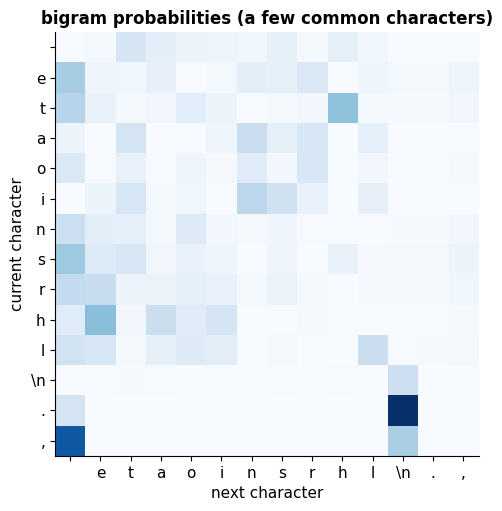

In [2]:
counts = torch.zeros(V, V)
for a, b in zip(train_data[:-1].tolist(), train_data[1:].tolist()): counts[a, b] += 1
P_bigram = (counts + 1) / (counts + 1).sum(1, keepdim=True)            # +1: Laplace smoothing (notebook 09)
nll = lambda P, d: -torch.log(P[d[:-1], d[1:]]).mean().item()
print(f"bigram model: train loss {nll(P_bigram, train_data):.3f}, validation loss {nll(P_bigram, val_data):.3f} nats/char   (uniform: log {V} = {math.log(V):.3f})")

g = torch.Generator().manual_seed(0); idx = stoi["\n"]; out = []
for _ in range(300): idx = torch.multinomial(P_bigram[idx], 1, generator=g).item(); out.append(itos[idx])
print("\nsample from the bigram model:\n" + "".join(out))

show = [stoi[c] for c in " etaoinsrhl\n.,"]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(P_bigram[show][:, show], cmap="Blues"); ax.grid(False)
labels = [repr(itos[i])[1:-1] for i in show]
ax.set(xticks=range(len(show)), yticks=range(len(show)), xticklabels=labels, yticklabels=labels, xlabel="next character", ylabel="current character", title="bigram probabilities (a few common characters)")
plt.show()

The bigram model knows that "h" often follows "t" and that spaces follow periods, so its output has word-like rhythm, but no actual words: one character of context isn't enough. Its validation loss, about 2.5 nats per character, is our baseline. (This count table is exactly what a neural network with an embedding layer and nothing else would learn.)

---
## 3. The averaging trick

To use more context, each position needs to gather information from **all** previous positions. The crudest version: represent position $t$ by the **average** of the vectors at positions $1, \dots, t$. A loop does it, but there's a much better way that's at the heart of attention: averaging is multiplication by a lower-triangular weight matrix.

In [3]:
torch.manual_seed(1)
T_, C_ = 5, 3
x = torch.randn(T_, C_)                                    # 5 positions, each a 3-dim vector

# Version 1: a loop
avg_loop = torch.stack([x[:t + 1].mean(0) for t in range(T_)])

# Version 2: a matrix multiplication with a lower-triangular weight matrix
W = torch.tril(torch.ones(T_, T_)); W = W / W.sum(1, keepdim=True)
avg_mat = W @ x

# Version 3: the same weights, built with softmax over scores where the future is masked to −∞
scores = torch.zeros(T_, T_).masked_fill(torch.tril(torch.ones(T_, T_)) == 0, float("-inf"))
W_soft = F.softmax(scores, dim=1)
print("weights (version 3):\n", W_soft.numpy().round(3))
print("all three versions agree:", torch.allclose(avg_loop, avg_mat), torch.allclose(avg_mat, W_soft @ x))

weights (version 3):
 [[1.    0.    0.    0.    0.   ]
 [0.5   0.5   0.    0.    0.   ]
 [0.333 0.333 0.333 0.    0.   ]
 [0.25  0.25  0.25  0.25  0.   ]
 [0.2   0.2   0.2   0.2   0.2  ]]
all three versions agree: True True


Row $t$ of the weight matrix says how much position $t$ takes from each earlier position; the zeros above the diagonal mean **no peeking at the future** (which would be cheating when predicting the next token). Version 3 is the key: if the scores weren't all zero but **depended on the content** of the positions, softmax would turn them into data-dependent weights. Some past positions would matter more than others, depending on what's there. That's attention.

---
## 4. Self-attention

Each position emits three vectors, all computed by linear layers from its current representation $x_t$:

- a **query** $q_t = W_Q x_t$: "what am I looking for?"
- a **key** $k_s = W_K x_s$: "what do I contain?"
- a **value** $v_s = W_V x_s$: "what will I hand over if you attend to me?"

Position $t$ scores each earlier position $s$ by the dot product $q_t \cdot k_s$ (high when what $t$ looks for matches what $s$ offers), turns the scores into weights with a softmax, and takes the weighted average of the values:

$$\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}} + M\Big)V,$$

where $M$ is the causal mask (0 on and below the diagonal, $-\infty$ above). It's a **soft dictionary lookup**: the query is compared with every key, and instead of returning the single best match, attention returns a blend of values weighted by how well each key matched. CX lecture 22 describes it as *"flattening the RNN"*: rather than passing information through a chain of states, every position connects to every earlier position directly, in one step.

In [4]:
class Head(nn.Module):
    """One head of causal self-attention, written out step by step."""
    def __init__(self, d_model, d_head, block):
        super().__init__()
        self.q, self.k, self.v = (nn.Linear(d_model, d_head, bias=False) for _ in range(3))
        self.register_buffer("mask", torch.tril(torch.ones(block, block)).bool())
    def forward(self, x, return_weights=False):
        B, T, _ = x.shape
        q, k, v = self.q(x), self.k(x), self.v(x)                         # (B, T, d_head) each
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])          # (B, T, T): every query against every key
        scores = scores.masked_fill(~self.mask[:T, :T], float("-inf"))     # no attending to the future
        w = F.softmax(scores, dim=-1)                                       # each row sums to 1
        out = w @ v                                                         # weighted average of values
        return (out, w) if return_weights else out

torch.manual_seed(0); h = Head(d_model=16, d_head=8, block=8)
xs = torch.randn(1, 6, 16); out, w = h(xs, return_weights=True)
print("output shape:", tuple(out.shape)); print("attention weights (row t = how position t spreads its attention):\n", w[0].detach().numpy().round(2))
ref = F.scaled_dot_product_attention(h.q(xs), h.k(xs), h.v(xs), is_causal=True)
print("matches PyTorch's built-in scaled_dot_product_attention:", torch.allclose(out, ref, atol=1e-6))

output shape: (1, 6, 8)
attention weights (row t = how position t spreads its attention):
 [[1.   0.   0.   0.   0.   0.  ]
 [0.41 0.59 0.   0.   0.   0.  ]
 [0.3  0.46 0.24 0.   0.   0.  ]
 [0.45 0.16 0.21 0.18 0.   0.  ]
 [0.3  0.16 0.13 0.23 0.19 0.  ]
 [0.12 0.2  0.17 0.19 0.16 0.15]]
matches PyTorch's built-in scaled_dot_product_attention: True


### Why divide by $\sqrt{d_k}$?

If the entries of $q$ and $k$ are roughly independent with variance 1, their dot product is a sum of $d_k$ terms and has variance $d_k$. With large $d_k$, the scores become large, the softmax saturates to nearly one-hot, and its gradients vanish (the same saturation problem as sigmoids in notebook 19). Dividing by $\sqrt{d_k}$ brings the variance back to 1. 🎚️ **Change the head size** and compare the attention weights with and without scaling:

In [5]:
def scaling_demo(d_k=64):
    torch.manual_seed(0); q = torch.randn(d_k); K = torch.randn(10, d_k)
    raw, scaled = K @ q, K @ q / math.sqrt(d_k)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
    for ax, s, nm in [(axes[0], raw, "without scaling"), (axes[1], scaled, "divided by √d_k")]:
        p = F.softmax(s, 0).numpy(); ax.bar(range(10), p, color=C["red"] if nm.startswith("without") else C["blue"])
        ax.set(title=f"{nm}: score std {s.std():.1f}, largest weight {p.max():.2f}", xlabel="key", ylim=(0, 1.05))
    axes[0].set_ylabel("attention weight"); fig.suptitle(f"d_k = {d_k}", y=1.02); fig.tight_layout(); plt.show()

interact(scaling_demo, d_k=IntSlider(value=64, min=2, max=512, step=2, description="d_k"));

Without scaling, by $d_k = 64$ one key takes nearly all the weight; the softmax has become a hard argmax that barely learns. With scaling, the weights stay soft at any head size.

---
## 5. Masking, multiple heads, and positions

**Multiple heads.** One head computes one kind of relationship. Running several heads in parallel, each with its own $W_Q, W_K, W_V$ of size $d_{\text{model}}/h$, and concatenating their outputs lets the model attend to different things at once (one head might track the previous character, another the start of the current word, another a matching quote mark). The total cost is about the same as one big head.

**Positions.** Attention is a weighted average over a *set*: shuffle the input positions and the outputs shuffle the same way, with no other change. By itself it has no idea of order. So we **add a positional embedding**, a learned vector for each position $0, 1, \dots, T-1$, to each token's embedding before the first block. (The original transformer used fixed sinusoids; many modern LLMs use rotary embeddings, RoPE, which rotate queries and keys by position-dependent angles.)

In [6]:
torch.manual_seed(0); h_nomask = Head(16, 8, 8); h_nomask.mask.fill_(True)       # attention without the causal mask
xs = torch.randn(1, 6, 16); perm = torch.tensor([3, 0, 5, 1, 4, 2])
out1 = h_nomask(xs); out2 = h_nomask(xs[:, perm])
print("unmasked attention, without positional information, is permutation-equivariant:", torch.allclose(out1[:, perm], out2, atol=1e-6))
pos = torch.randn(1, 6, 16)
print("after adding positional embeddings it isn't any more:", torch.allclose(h_nomask(xs + pos)[:, perm], h_nomask(xs[:, perm] + pos), atol=1e-6))

unmasked attention, without positional information, is permutation-equivariant: True
after adding positional embeddings it isn't any more: False


---
## 6. The transformer block

A GPT is a stack of identical blocks. Each block has two sub-layers, both wrapped in a **residual connection** (notebook 21) and preceded by **layer normalization** (normalize each position's vector to zero mean and unit variance across its features, then rescale):

$$x \leftarrow x + \mathrm{MultiHeadAttention}(\mathrm{LN}(x)), \qquad x \leftarrow x + \mathrm{MLP}(\mathrm{LN}(x)).$$

- **Attention** is where positions **communicate**: information moves between tokens.
- The **MLP** (two linear layers with a GELU in between, 4× wider in the middle) is where each position **computes** on what it gathered, independently.
- The **residual stream** $x$ runs through the whole network; each sub-layer reads from it and adds a correction. As with ResNets, this keeps gradients healthy through many layers.

On top: token embedding + positional embedding at the bottom, a final layer norm, and a linear layer to vocabulary-sized logits. That's the whole GPT architecture (CX lecture 22: *"multi-layer, multi-headed self-attention with residual connections"*).

In [7]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, block, dropout=0.0):
        super().__init__(); assert d_model % n_heads == 0
        self.n_heads = n_heads; self.qkv = nn.Linear(d_model, 3 * d_model); self.proj = nn.Linear(d_model, d_model); self.drop = nn.Dropout(dropout)
        self.register_buffer("mask", torch.tril(torch.ones(block, block)).bool())
    def forward(self, x, return_weights=False):
        B, T, D = x.shape; hd = D // self.n_heads
        q, k, v = self.qkv(x).split(D, dim=2)
        q, k, v = [z.view(B, T, self.n_heads, hd).transpose(1, 2) for z in (q, k, v)]          # (B, heads, T, hd): all heads at once
        w = (q @ k.transpose(-2, -1) / math.sqrt(hd)).masked_fill(~self.mask[:T, :T], float("-inf")).softmax(-1)
        out = (self.drop(w) @ v).transpose(1, 2).reshape(B, T, D)                                 # concatenate the heads
        out = self.proj(out)
        return (out, w) if return_weights else out

class Block(nn.Module):
    def __init__(self, d_model, n_heads, block, dropout=0.0):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, block, dropout)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model), nn.Dropout(dropout))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))          # communicate
        return x + self.mlp(self.ln2(x))         # compute

class GPT(nn.Module):
    def __init__(self, vocab, d_model=128, n_heads=4, n_layers=4, block=128, dropout=0.0):
        super().__init__(); self.block = block
        self.tok = nn.Embedding(vocab, d_model); self.pos = nn.Embedding(block, d_model)
        self.blocks = nn.ModuleList([Block(d_model, n_heads, block, dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model); self.head = nn.Linear(d_model, vocab)
    def forward(self, idx):
        T = idx.shape[1]; x = self.tok(idx) + self.pos(torch.arange(T, device=idx.device))
        for b in self.blocks: x = b(x)
        return self.head(self.ln_f(x))
    @torch.no_grad()
    def generate(self, idx, n, temperature=1.0, generator=None):
        for _ in range(n):
            logits = self(idx[:, -self.block:])[:, -1] / temperature          # only the last position's prediction matters
            nxt = torch.multinomial(F.softmax(logits, -1).cpu(), 1, generator=generator).to(idx.device)
            idx = torch.cat([idx, nxt], 1)
        return idx

torch.manual_seed(0); gpt = GPT(V).to(device)
print(f"mini-GPT: {sum(p.numel() for p in gpt.parameters()):,} parameters (GPT-2 small: 124 million; GPT-3: 175 billion)")
xb = torch.randint(0, V, (2, 16)).to(device)
print("input", tuple(xb.shape), "→ logits", tuple(gpt(xb).shape), "(a next-character distribution at every position)")

mini-GPT: 826,433 parameters (GPT-2 small: 124 million; GPT-3: 175 billion)
input (2, 16) → logits (2, 16, 65) (a next-character distribution at every position)


---
## 7. Training the mini-GPT

One forward pass on a 128-character window produces 128 predictions at once (position $t$ predicts character $t+1$ using only characters $\le t$, thanks to the mask), so every window gives 128 training examples in parallel. That parallelism, impossible for an RNN, is a big part of why transformers won.

In [8]:
B_, T_BLOCK, STEPS = 32, 128, 2500                 # ~10 minutes on a CPU; on a GPU, try a bigger model and 5000+ steps
def get_batch(src):
    ix = torch.randint(0, len(src) - T_BLOCK - 1, (B_,))
    return torch.stack([src[i:i + T_BLOCK] for i in ix]).to(device), torch.stack([src[i + 1:i + T_BLOCK + 1] for i in ix]).to(device)

@torch.no_grad()
def estimate_loss(model, n=20):
    model.eval(); out = {}
    for name, src in [("train", train_data), ("val", val_data)]:
        out[name] = np.mean([F.cross_entropy(model(x).view(-1, V), y.view(-1)).item() for x, y in (get_batch(src) for _ in range(n))])
    model.train(); return out

torch.manual_seed(0); gpt = GPT(V).to(device)
opt = torch.optim.AdamW(gpt.parameters(), lr=2e-3, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=STEPS, pct_start=0.1)    # warm up, then anneal
curve, samples, t0 = [], {}, time.time()
for step in range(STEPS + 1):
    if step % 250 == 0:
        L = estimate_loss(gpt); curve.append((step, L["train"], L["val"]))
        print(f"step {step:5d}: train {L['train']:.3f}  val {L['val']:.3f}  ({time.time() - t0:.0f}s)")
    if step in (0, 500, STEPS):
        samples[step] = decode(gpt.generate(torch.tensor([encode("ROMEO:\n")], device=device), 300, temperature=0.8, generator=torch.Generator().manual_seed(0))[0].tolist())
    if step == STEPS: break
    x, y = get_batch(train_data)
    loss = F.cross_entropy(gpt(x).view(-1, V), y.view(-1))
    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0); opt.step(); sched.step()

step     0: train 4.295  val 4.287  (5s)


step   250: train 2.301  val 2.332  (72s)


step   500: train 1.830  val 1.960  (137s)


step   750: train 1.639  val 1.781  (203s)


step  1000: train 1.523  val 1.704  (267s)


...

step  1500: train 1.424  val 1.639  (394s)


step  1750: train 1.379  val 1.590  (461s)


step  2000: train 1.362  val 1.570  (526s)


step  2250: train 1.338  val 1.542  (592s)


step  2500: train 1.335  val 1.578  (656s)


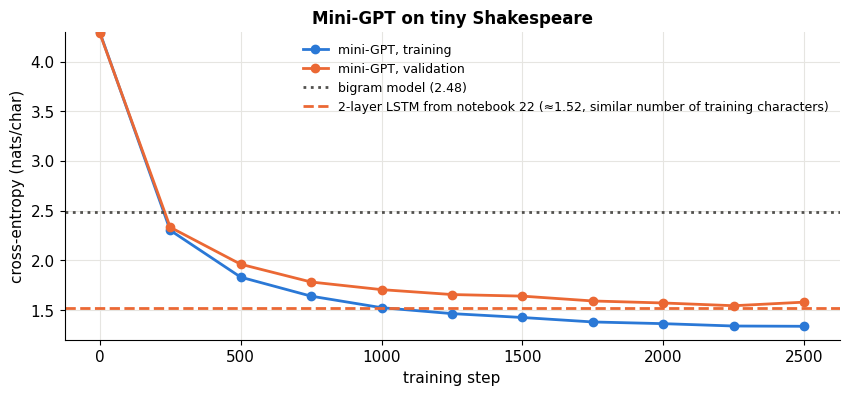

========== after 0 steps ==========
ROMEO:
tPZrjMhVcdkhRxLsX?gqWHoHKa
?ePhjoU&oNdwIg
lsvSBUMyhoUu$BygXvBntw
kVrM h&?j DoR!.OEJelC!BTg3eerPQjsN.p-B3KyporWi&kMveJIRc:$zO;qJU,dRr?nH- mj$fxttoAHMLpwPjJR;f.HR'SxIiUe$votg,dkJDSc j' sCuz.B3u!Sn..SVqHItVe3xfSp-P$
-Oi$HATWVeQnNHssKNf;iztcH3qqdg'Oro&OwiA$'zK'kIRdZV;Q,n..x.Vin?FSxyYL&Oq'EMgq3;VvYxNE3hV

========== after 500 steps ==========
ROMEO:
Thore his kis henly Wadood mears!

LAUFIO:
I have how, with for bear? hear this beielins.
If him some so your well exchersend died:
Wear my fatter well you for man is over.

She SI Spir Your drar.

SICINIUS:
Than
This mato snows are in comeloung of with bing.

GLEO:
As toin, Spaten to Mast the my ha

========== after 2500 steps ==========
ROMEO:
Thou must know sell me Henryer,
And in the strengths upon thintender change.

QUEEN MARGARET:
Peter, though this permity send with a land.

DUKE VINCENTIO:
What's I seek to do the brother thus new for
The rage his fillow,--

CORIOLANUS:
The duke of with the meas

In [9]:
cv = np.array(curve)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cv[:, 0], cv[:, 1], "o-", label="mini-GPT, training"); ax.plot(cv[:, 0], cv[:, 2], "o-", label="mini-GPT, validation")
ax.axhline(nll(P_bigram, val_data), color=C["muted"], ls=":", label=f"bigram model ({nll(P_bigram, val_data):.2f})")
ax.axhline(1.52, color=C["orange"], ls="--", label="2-layer LSTM from notebook 22 (≈1.52, similar number of training characters)")
ax.set(xlabel="training step", ylabel="cross-entropy (nats/char)", ylim=(1.2, 4.3), title="Mini-GPT on tiny Shakespeare"); ax.legend(fontsize=9)
plt.show()
for step, s in samples.items(): print(f"========== after {step} steps ==========\n{s}\n")

The mini-GPT falls far below the bigram baseline and ends in the same range as notebook 22's LSTM, which was trained on a similar number of characters. At this tiny scale the two architectures are close; the transformer's advantages show up at scale: it trains on all positions in parallel (fast on GPUs), connects distant positions in one step instead of through a long chain, and keeps improving as models and data grow, which is what made 100-billion-parameter language models possible. The samples show the same progression as the LSTM: gibberish, then words and formatting, then pseudo-Shakespeare with speaker names and verse-like lines.

🎚️ **Sample with your own prompt length and temperature:**

In [10]:
def gpt_sample(temperature=0.8, seed=0):
    out = gpt.generate(torch.tensor([encode("KING HENRY:\n")], device=device), 300, temperature=temperature, generator=torch.Generator().manual_seed(seed))
    print(decode(out[0].tolist()))

interact(gpt_sample, temperature=FloatSlider(value=0.8, min=0.2, max=2.0, step=0.1, description="τ"), seed=IntSlider(value=0, min=0, max=5, description="seed"));

---
## 8. Looking inside: what do the heads attend to?

Run a line of text through the trained model and draw each head's attention weights in the first and last layers: row $t$ shows where position $t$ looked when predicting the next character.

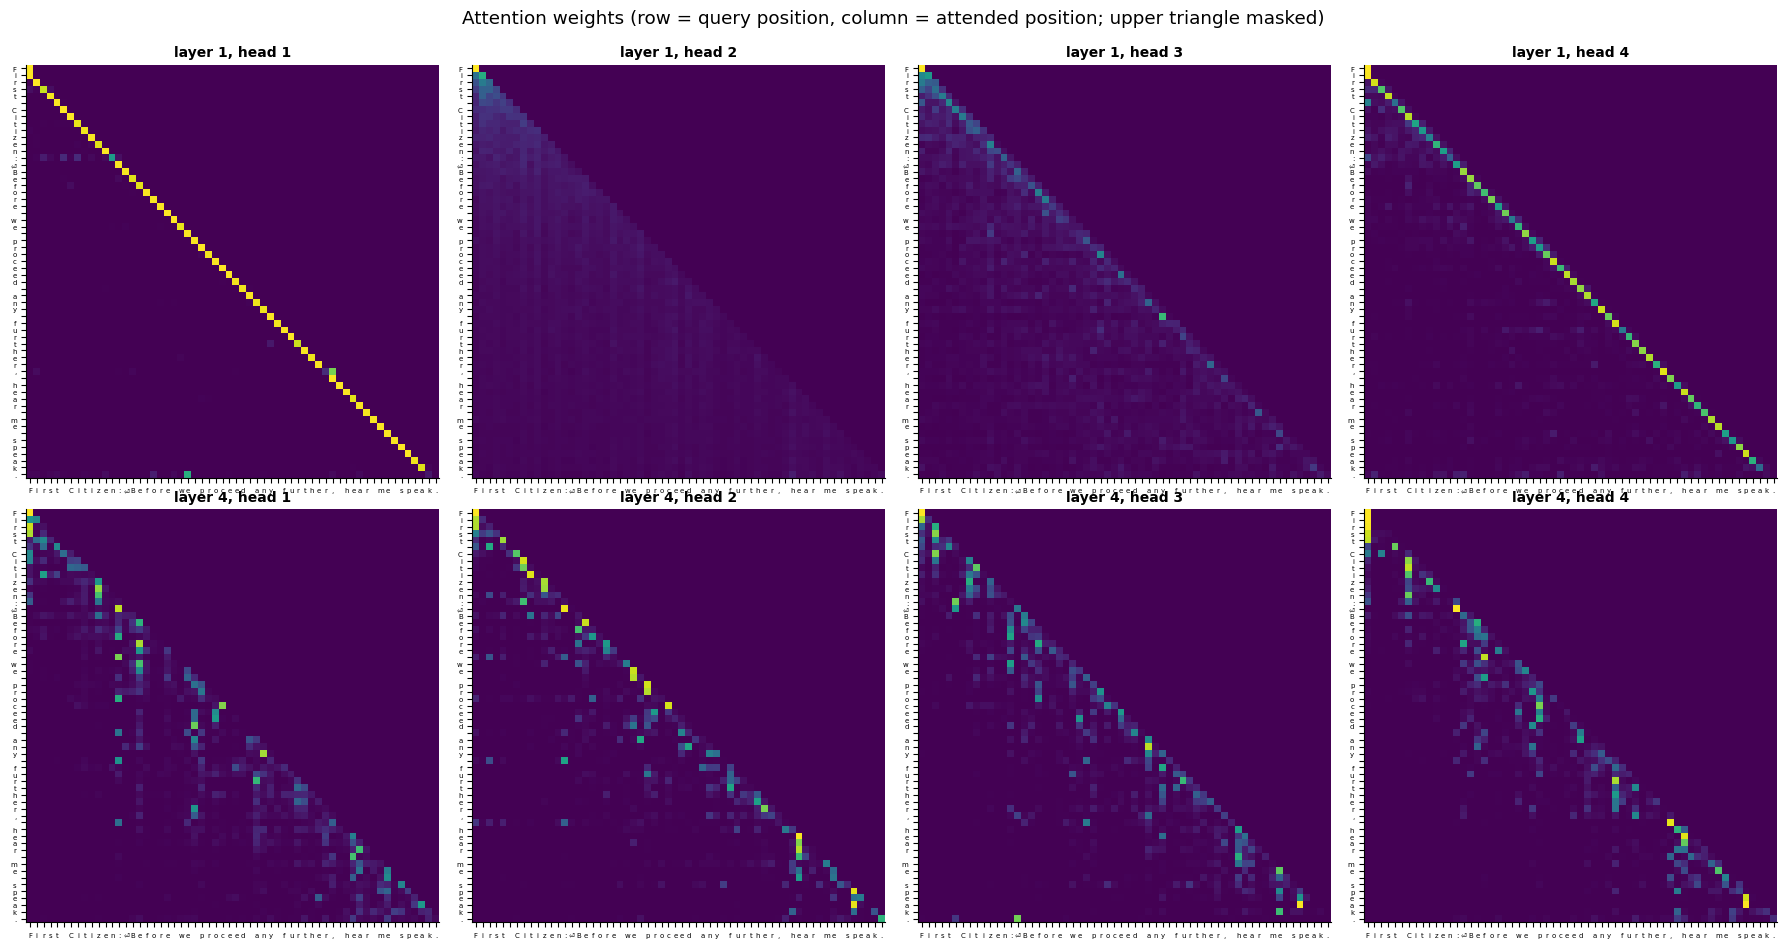

average attention to the immediately preceding character, per layer (rows) and head (columns):
         head 1  head 2  head 3  head 4
layer 1    0.95    0.07    0.20    0.71
layer 2    0.44    0.30    0.34    0.40
layer 3    0.07    0.34    0.35    0.28
layer 4    0.17    0.23    0.17    0.25


In [11]:
probe_text = "First Citizen:\nBefore we proceed any further, hear me speak."
ids = torch.tensor([encode(probe_text)], device=device)
gpt.eval(); weights = []
with torch.no_grad():
    x = gpt.tok(ids) + gpt.pos(torch.arange(ids.shape[1], device=device))
    for b in gpt.blocks:
        _, w = b.attn(b.ln1(x), return_weights=True); weights.append(w[0].cpu()); x = b(x)
labels = [c if c != "\n" else "⏎" for c in probe_text]
fig, axes = plt.subplots(2, 4, figsize=(18, 9.4))
for row, layer in enumerate([0, len(weights) - 1]):
    for hh in range(4):
        ax = axes[row, hh]; ax.imshow(weights[layer][hh], cmap="viridis"); ax.grid(False)
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=5); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=5)
        ax.set_title(f"layer {layer + 1}, head {hh + 1}", fontsize=10)
fig.suptitle("Attention weights (row = query position, column = attended position; upper triangle masked)", y=0.995); fig.tight_layout(); plt.show()

prev_weight = [[weights[l][hh].diagonal(-1).mean().item() for hh in range(4)] for l in range(len(weights))]
print("average attention to the immediately preceding character, per layer (rows) and head (columns):")
print(pd.DataFrame(prev_weight, index=[f"layer {l + 1}" for l in range(len(weights))], columns=[f"head {h + 1}" for h in range(4)]).round(2).to_string())

Some heads show a strong stripe just below the diagonal: they mostly look at the previous one or two characters, a learned version of the bigram model, useful for spelling. Others spread their attention over the current word or jump back to spaces, punctuation, or the start of the line, gathering longer-range context such as "we are inside a speaker's name" or "this word started with a capital letter". Interpreting heads in real LLMs is an active research field (mechanistic interpretability), which has found heads that copy earlier tokens ("induction heads"), track syntax, and more.

---
## 9. Tokenization: byte-pair encoding

We've used characters as tokens: a tiny vocabulary, but long sequences (each word costs several positions, and attention's cost grows with the square of the length). Real LLMs use **subword tokens** built by **byte-pair encoding** (BPE): start from characters (or bytes), then repeatedly merge the most frequent adjacent pair into a new token. Frequent words become single tokens; rare words split into pieces. Here's BPE from scratch on our text:

In [12]:
def bpe_train(ids, n_merges):
    ids = list(ids); merges = {}; next_id = V
    for _ in range(n_merges):
        pairs = {}
        for a, b in zip(ids, ids[1:]): pairs[(a, b)] = pairs.get((a, b), 0) + 1
        best = max(pairs, key=pairs.get); merges[best] = next_id
        new, i = [], 0                                               # replace every occurrence of the pair with the new token
        while i < len(ids):
            if i < len(ids) - 1 and (ids[i], ids[i + 1]) == best: new.append(next_id); i += 2
            else: new.append(ids[i]); i += 1
        ids = new; next_id += 1
    return merges, ids

vocab_str = {i: itos[i] for i in range(V)}
sample_ids = encode(text[:100000])
t0 = time.time(); merges, compressed = bpe_train(sample_ids, 300)
for (a, b), new in merges.items(): vocab_str[new] = vocab_str[a] + vocab_str[b]
print(f"300 merges in {time.time() - t0:.0f}s: {len(sample_ids):,} characters → {len(compressed):,} tokens ({len(sample_ids) / len(compressed):.2f} characters per token)")
print("first 20 merges:", [vocab_str[n] for n in list(merges.values())[:20]])
print("some later merges:", [vocab_str[n] for n in list(merges.values())[250:270]])

def bpe_encode(s):
    ids = encode(s)
    for (a, b), new in merges.items():                                 # apply merges in the order they were learned
        out, i = [], 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == a and ids[i + 1] == b: out.append(new); i += 2
            else: out.append(ids[i]); i += 1
        ids = out
    return ids
line = "My lord, the king hath sent for you."
print("\n" + " | ".join(vocab_str[t] for t in bpe_encode(line)))

300 merges in 7s: 100,000 characters → 45,539 tokens (2.20 characters per token)
first 20 merges: ['e ', 'th', 't ', 's ', 'ou', ', ', 'd ', 'er', 'an', 'in', ':\n', ' th', 'en', '\n\n', 'or', 'on', 'y ', 'ar', 'o ', 'ha']
some later merges: [' them', 'with ', 'shall ', '\nH', '\nThe ', 'el', 'k ', 'Rom', 'we ', 'know', 'to the ', 'people', 'for ', 'gi', 'MINIUS:\n', "'ll ", 'mor', 'po', 'ust ', 'sen']

M | y  | l | or | d,  | the  | k | ing  | ha | th |  s | en | t  | for |  you | .


The first merges join common letter pairs ("e " and "th"), later ones build whole common words and word pieces. The same sentence becomes far fewer tokens, so a model with a fixed context window sees more text. GPT-2 used about 50,000 BPE tokens; recent models use 100,000–200,000. Tokenization has visible side effects: models are worse at character-level tasks (spelling, counting letters) because they never see individual characters, and text in languages underrepresented in the tokenizer's training data costs more tokens.

---
## 10. Scaling up

**Cost.** Attention compares every position with every earlier one: $O(T^2)$ time and memory per layer for a sequence of length $T$ (CX lecture 22: *"limitations? expensive computation"*). Doubling the context window quadruples attention's cost, which is why long-context models use tricks such as FlashAttention (computing attention in tiles without storing the full $T \times T$ matrix), sparse or sliding-window attention, and more.

**The KV cache.** When generating, each new token only needs its own query, but it attends to the keys and values of all previous tokens. Those don't change, so they're cached instead of recomputed: generating $n$ tokens costs $O(n)$ forward work per token rather than reprocessing the whole sequence. (Our `generate` recomputes everything for simplicity.)

**Scaling laws.** Kaplan et al. (2020) and Hoffmann et al. (2022, "Chinchilla") found that a language model's loss falls as a smooth power law in model size, data, and compute, as long as they're scaled together (roughly 20 training tokens per parameter for compute-optimal training). That predictability is why labs trained ever larger models:

| Model | Year | Parameters | Training tokens |
|---|---|---|---|
| our mini-GPT | today | 0.8 M | ~10 M characters |
| GPT-2 | 2019 | 1.5 B | ~10 B |
| GPT-3 | 2020 | 175 B | 300 B |
| Chinchilla | 2022 | 70 B | 1.4 T |

**What pretraining gives you, and what it doesn't.** A pretrained model is a superb *continuer* of text: it has absorbed grammar, facts, styles, and patterns of reasoning. But it isn't an assistant. Prompt it with a question and it may continue with more questions, or with the kind of text that typically follows that question on the internet. CX lecture 23 asks: *"Is pretraining enough?"* No. Turning a text predictor into a helpful, honest assistant takes **post-training**: supervised fine-tuning on demonstrations, then learning from preferences with reinforcement learning or DPO. That's the final notebook.

---
## 11. Summary

- An LLM is an **autoregressive categorical model**: $p(x) = \prod_t p(x_t \mid x_{<t})$, trained by maximum likelihood (next-token cross-entropy) on unlabeled text.
- **Attention** is a learnable, content-dependent weighted average: $\mathrm{softmax}(QK^\top/\sqrt{d_k} + M)V$. Queries ask, keys advertise, values deliver; the **causal mask** forbids looking ahead; $\sqrt{d_k}$ keeps the softmax from saturating.
- **Multi-head** attention runs several lookups in parallel; **positional embeddings** supply the order that attention alone ignores.
- A **transformer block** = attention (tokens communicate) + MLP (tokens compute), each with layer norm and a residual connection. A GPT stacks these blocks between an embedding layer and a softmax over the vocabulary.
- Transformers train on all positions in parallel and connect distant tokens directly; their cost grows as $T^2$ in sequence length. **BPE** tokens shorten sequences. Loss follows predictable **scaling laws**.
- Pretraining produces a text continuer, not an assistant: **post-training** is next.

### ✏️ Exercises

1. Show that without the $\sqrt{d_k}$ scaling, $\mathrm{Var}(q \cdot k) = d_k$ when $q$ and $k$ have independent zero-mean, unit-variance entries.
2. Remove the positional embeddings from the mini-GPT and retrain for 1,000 steps. How much worse is the loss? Why isn't it as bad as you might expect for a causal model? (Hint: the mask itself leaks some position information.)
3. Implement a **KV cache** in `generate`: store each layer's keys and values and feed only the newest token at each step. Check that the outputs match and measure the speedup for 500 generated characters.
4. Retrain the mini-GPT on the BPE tokens from section 9 (vocabulary 65 + 300) with the same number of steps and block size. Compare samples. Is the loss comparable? (Convert to nats per *character* first.)
5. Train with 1, 2, 4, and 8 layers (same width) for the same number of steps and plot validation loss against parameter count on log axes. Do you see a power law?
6. Find an "induction head": construct a sequence like "abcxyz…abcxy" and check whether some head in the last layer attends from the second "x" to the character right after the first "x".

### References

- CX 4240 lecture 22 ((Large) Language Model Part I: Attention and Transformers).
- A. Vaswani et al., *Attention Is All You Need*, NeurIPS (2017).
- A. Radford et al., *Improving Language Understanding by Generative Pre-Training* (GPT, 2018); *Language Models are Unsupervised Multitask Learners* (GPT-2, 2019); T. Brown et al., *Language Models are Few-Shot Learners* (GPT-3), NeurIPS (2020).
- D. Bahdanau, K. Cho & Y. Bengio, *Neural Machine Translation by Jointly Learning to Align and Translate* (2014).
- R. Sennrich, B. Haddow & A. Birch, *Neural Machine Translation of Rare Words with Subword Units* (BPE), ACL (2016).
- J. Kaplan et al., *Scaling Laws for Neural Language Models* (2020); J. Hoffmann et al., *Training Compute-Optimal Large Language Models* (Chinchilla), NeurIPS (2022).
- C. Olsson et al., *In-context Learning and Induction Heads* (2022).
- A. Karpathy, *Let's build GPT: from scratch, in code, spelled out* (video) and nanoGPT; J. Alammar, *The Illustrated Transformer* (blog).

**Next → [26 · LLM Post-Training](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/26_llm_post_training.ipynb)**